# Project 02: Data Visualization with Matplotlib & Seaborn
**Domain:** Data Science & AI | **Level:** Beginner | **Estimated Time:** ~6 hours  
**Learner Guide Reference:** InternCircle Project 02

---

## 1. Project Overview & Requirements
Effective data visualization bridges raw numbers and human insight. This project analyzes the classic **Tips dataset** using `matplotlib` and `seaborn` to answer specific business questions regarding customer spending, tipping behaviors, and party dynamics.

### Requirements Checklist
- [x] **Bar charts and scatter plots** with semantic hue differentiation
- [x] **Correlation heatmap generation** with Pearson correlation coefficients and annotations
- [x] **Custom color palettes and plot formatting** (color-blind friendly palettes: `deep`, `Blues`)
- [x] **Clear and honest visualizations**: Zero baselines on bar charts, sensible axis ranges, no misleading 3D or pie charts
- [x] **Informative chart titles**: Titles state the *finding* rather than merely listing variable names
- [x] **Labels with units**: Currency in `USD ($)`, counts, and categories clearly marked
- [x] **One-line takeaway under every chart** stating the core insight
- [x] **Dashboard grid export**: 2x2 multi-panel figure saved at 150 DPI (`tips_overview.png`)


In [1]:
# Step 0: Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set global aesthetic theme and font sizes
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.titlesize": 16,
    "figure.autolayout": False
})

print("Libraries imported and theme configured.")


Libraries imported and theme configured.


## 2. Dataset Exploration
We load the `tips` dataset from `seaborn`. This benchmark dataset records 244 dining transactions collected by a restaurant server over several months.


In [2]:
# Load the dataset
tips = sns.load_dataset("tips")

# Display initial rows and structure
print("Dataset Shape:", tips.shape)
tips.head()


Dataset Shape: (244, 7)


,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [3]:
# Check data types, null values, and summary statistics
tips.info()


<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    category
 3   smoker      244 non-null    category
 4   day         244 non-null    category
 5   time        244 non-null    category
 6   size        244 non-null    int64   
dtypes: category(4), float64(2), int64(1)
memory usage: 7.4 KB


In [4]:
# Summary statistics for numeric features
tips.describe()


,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


## 3. Chart 1: Distribution of Total Bill Amounts (Histogram)
* **Research Question:** How are customer bills distributed across dining parties?
* **Chart Selection:** Histogram with Kernel Density Estimation (KDE) to display univariate distribution, central tendency, spread, and skewness.


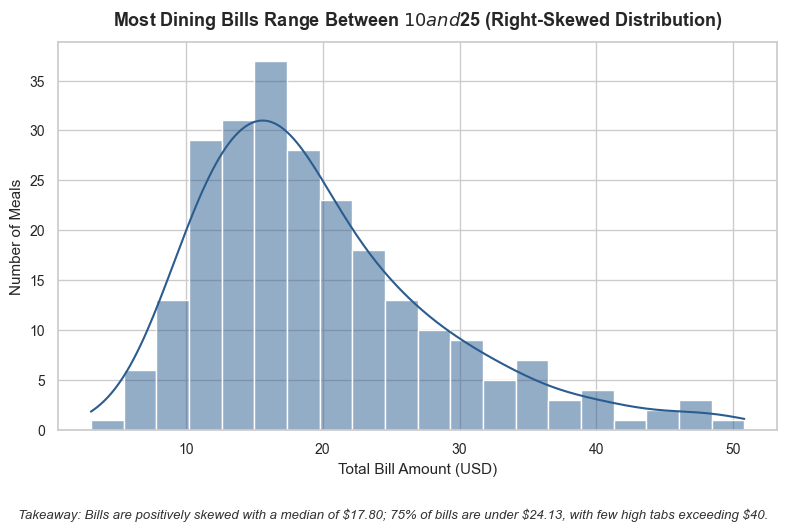

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.histplot(tips["total_bill"], bins=20, kde=True, color="#2b5c8f", ax=ax)

ax.set_title("Most Dining Bills Range Between $10 and $25 (Right-Skewed Distribution)", 
             fontweight="bold", pad=12)
ax.set_xlabel("Total Bill Amount (USD)")
ax.set_ylabel("Number of Meals")

# Add takeaway note below chart
fig.text(0.5, -0.05, 
         "Takeaway: Bills are positively skewed with a median of $17.80; 75% of bills are under $24.13, with few high tabs exceeding $40.",
         ha="center", fontsize=9.5, style="italic", color="#333333")

plt.tight_layout()
plt.show()


## 4. Chart 2: Tip Amounts Across Days of the Week (Box Plot)
* **Research Question:** Do tip amounts significantly differ across days of the week?
* **Chart Selection:** Box plot to compare median, interquartile range (IQR), and outliers across discrete categorical groups (Thur, Fri, Sat, Sun).


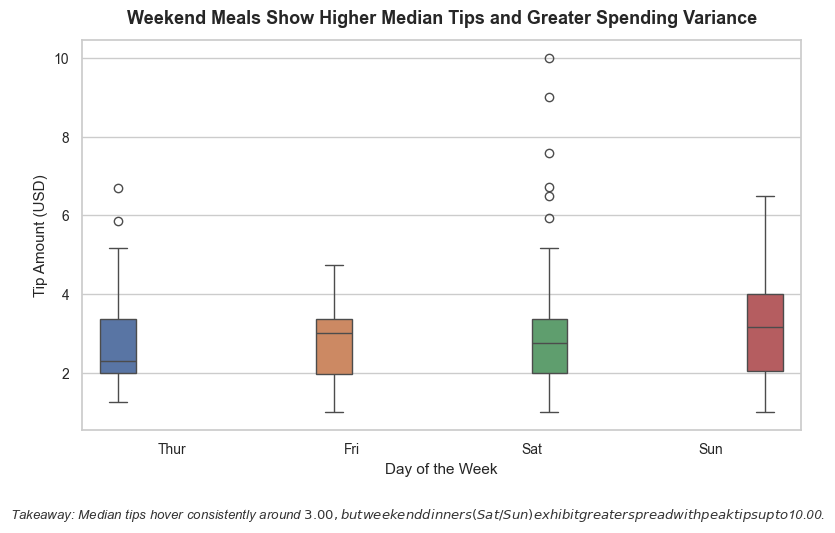

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=tips, x="day", y="tip", hue="day", palette="deep", legend=False, ax=ax)

ax.set_title("Weekend Meals Show Higher Median Tips and Greater Spending Variance", 
             fontweight="bold", pad=12)
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Tip Amount (USD)")

fig.text(0.5, -0.05, 
         "Takeaway: Median tips hover consistently around $3.00, but weekend dinners (Sat/Sun) exhibit greater spread with peak tips up to $10.00.",
         ha="center", fontsize=9.5, style="italic", color="#333333")

plt.tight_layout()
plt.show()


## 5. Chart 3: Total Bill vs. Tip Amount by Meal Time (Scatter Plot)
* **Research Question:** Does a bigger bill mean a bigger tip, and does dining time (Lunch vs. Dinner) modify this pattern?
* **Chart Selection:** Scatter plot with color coding (`hue='time'`) to show bivariate correlation and dining period segmentation.


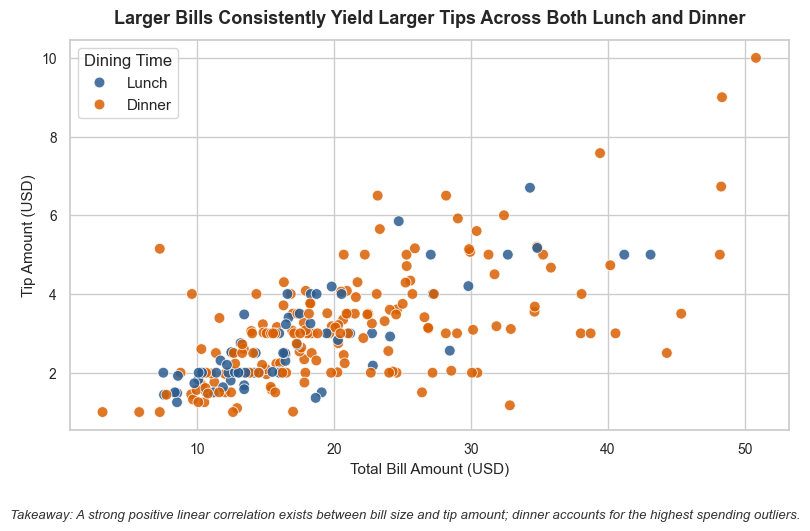

In [7]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", palette=["#2b5c8f", "#d95f02"], 
                alpha=0.85, s=60, ax=ax)

ax.set_title("Larger Bills Consistently Yield Larger Tips Across Both Lunch and Dinner", 
             fontweight="bold", pad=12)
ax.set_xlabel("Total Bill Amount (USD)")
ax.set_ylabel("Tip Amount (USD)")
ax.legend(title="Dining Time", loc="upper left")

fig.text(0.5, -0.05, 
         "Takeaway: A strong positive linear correlation exists between bill size and tip amount; dinner accounts for the highest spending outliers.",
         ha="center", fontsize=9.5, style="italic", color="#333333")

plt.tight_layout()
plt.show()


## 6. Chart 4: Average Bill by Day & Smoking Status (Bar Chart)
* **Research Question:** How does average bill size vary by day for smoking versus non-smoking parties?
* **Chart Selection:** Bar chart with 68% confidence intervals (error bars) and an honest zero-baseline.


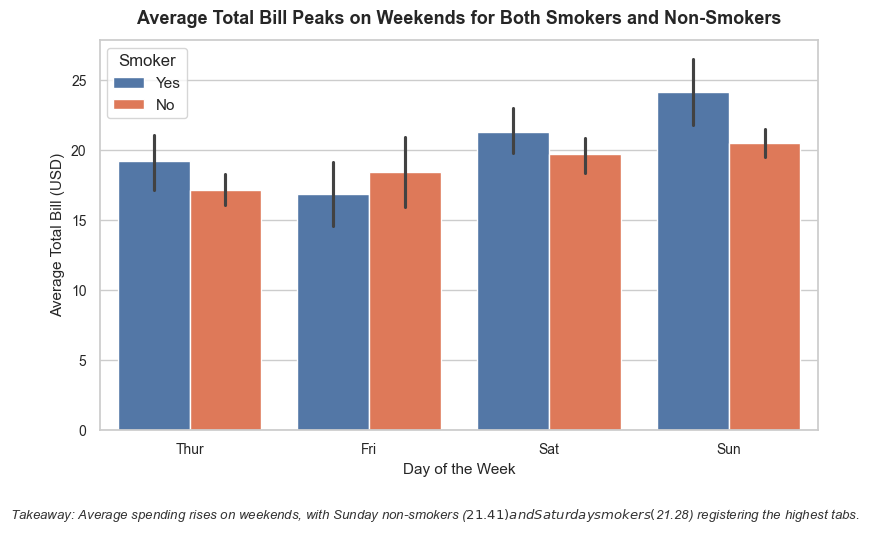

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=tips, x="day", y="total_bill", hue="smoker", palette=["#4575b4", "#f46d43"], 
            errorbar=("ci", 68), ax=ax)

ax.set_title("Average Total Bill Peaks on Weekends for Both Smokers and Non-Smokers", 
             fontweight="bold", pad=12)
ax.set_xlabel("Day of the Week")
ax.set_ylabel("Average Total Bill (USD)")
ax.set_ylim(bottom=0)  # Honest charting: zero baseline
ax.legend(title="Smoker", loc="upper left")

fig.text(0.5, -0.05, 
         "Takeaway: Average spending rises on weekends, with Sunday non-smokers ($21.41) and Saturday smokers ($21.28) registering the highest tabs.",
         ha="center", fontsize=9.5, style="italic", color="#333333")

plt.tight_layout()
plt.show()


## 7. Chart 5: Correlation Heatmap
* **Research Question:** Which numeric variables move together, and what is the single strongest linear relationship?
* **Chart Selection:** Heatmap of the Pearson correlation matrix with numeric labels (`annot=True`) and monochromatic color gradient (`cmap="Blues"`).


Correlation Matrix:
            total_bill       tip      size
total_bill    1.000000  0.675734  0.598315
tip           0.675734  1.000000  0.489299
size          0.598315  0.489299  1.000000


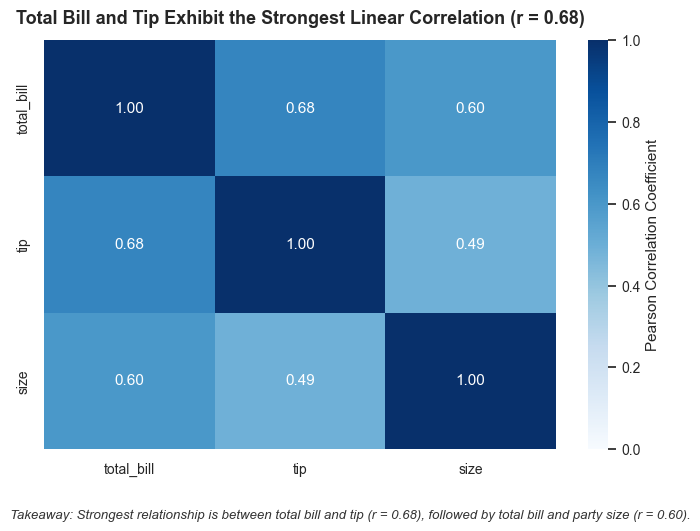

In [9]:
# Compute Pearson correlation matrix across numeric features
corr_matrix = tips.select_dtypes("number").corr()
print("Correlation Matrix:")
print(corr_matrix)

fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            cbar_kws={"label": "Pearson Correlation Coefficient"}, ax=ax)

ax.set_title("Total Bill and Tip Exhibit the Strongest Linear Correlation (r = 0.68)", 
             fontweight="bold", pad=12)

fig.text(0.5, -0.05, 
         "Takeaway: Strongest relationship is between total bill and tip (r = 0.68), followed by total bill and party size (r = 0.60).",
         ha="center", fontsize=9.5, style="italic", color="#333333")

plt.tight_layout()
plt.show()


## 8. Combined 2x2 Dashboard Image (`tips_overview.png`)
Per step 6 of the Learner Guide, we assemble four key visualizations in a 2x2 subplot grid and export it at **150 DPI**.


Saved 2x2 dashboard to tips_overview.png at 150 DPI.


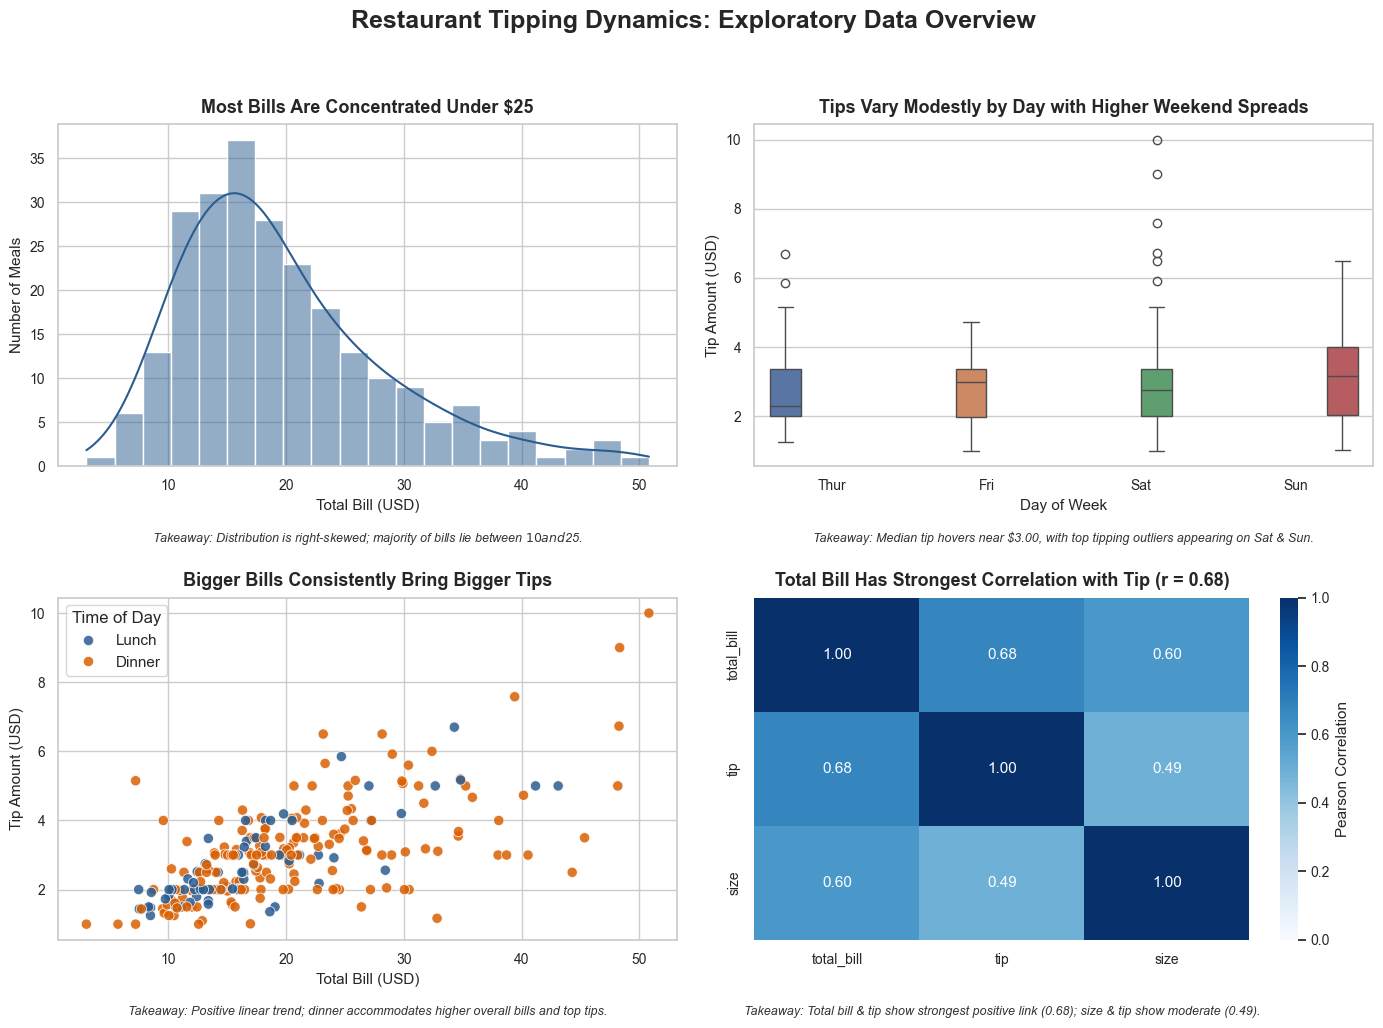

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
fig.suptitle("Restaurant Tipping Dynamics: Exploratory Data Overview", 
             fontsize=18, fontweight="bold", y=0.98)

# [0, 0]: Histogram
sns.histplot(tips["total_bill"], bins=20, kde=True, color="#2b5c8f", ax=axes[0, 0])
axes[0, 0].set_title("Most Bills Are Concentrated Under $25", fontweight="bold", pad=8)
axes[0, 0].set_xlabel("Total Bill (USD)")
axes[0, 0].set_ylabel("Number of Meals")
axes[0, 0].text(0.5, -0.22, "Takeaway: Distribution is right-skewed; majority of bills lie between $10 and $25.",
                transform=axes[0, 0].transAxes, ha="center", fontsize=9, style="italic", color="#333333")

# [0, 1]: Boxplot
sns.boxplot(data=tips, x="day", y="tip", hue="day", palette="deep", legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Tips Vary Modestly by Day with Higher Weekend Spreads", fontweight="bold", pad=8)
axes[0, 1].set_xlabel("Day of Week")
axes[0, 1].set_ylabel("Tip Amount (USD)")
axes[0, 1].text(0.5, -0.22, "Takeaway: Median tip hovers near $3.00, with top tipping outliers appearing on Sat & Sun.",
                transform=axes[0, 1].transAxes, ha="center", fontsize=9, style="italic", color="#333333")

# [1, 0]: Scatter plot
sns.scatterplot(data=tips, x="total_bill", y="tip", hue="time", palette=["#2b5c8f", "#d95f02"], 
                alpha=0.85, s=55, ax=axes[1, 0])
axes[1, 0].set_title("Bigger Bills Consistently Bring Bigger Tips", fontweight="bold", pad=8)
axes[1, 0].set_xlabel("Total Bill (USD)")
axes[1, 0].set_ylabel("Tip Amount (USD)")
axes[1, 0].legend(title="Time of Day", loc="upper left")
axes[1, 0].text(0.5, -0.22, "Takeaway: Positive linear trend; dinner accommodates higher overall bills and top tips.",
                transform=axes[1, 0].transAxes, ha="center", fontsize=9, style="italic", color="#333333")

# [1, 1]: Heatmap
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1,
            cbar_kws={"label": "Pearson Correlation"}, ax=axes[1, 1])
axes[1, 1].set_title("Total Bill Has Strongest Correlation with Tip (r = 0.68)", fontweight="bold", pad=8)
axes[1, 1].text(0.5, -0.22, "Takeaway: Total bill & tip show strongest positive link (0.68); size & tip show moderate (0.49).",
                transform=axes[1, 1].transAxes, ha="center", fontsize=9, style="italic", color="#333333")

plt.tight_layout(rect=[0, 0.04, 1, 0.95])
plt.savefig("tips_overview.png", dpi=150)
print("Saved 2x2 dashboard to tips_overview.png at 150 DPI.")
plt.show()


## 9. Honest Charting Review & Takeaway Summary

### Honest Charting Review (Checklist Verification)
1. **Axis Integrity:** Bar charts explicitly enforce `ax.set_ylim(bottom=0)` to avoid deceptive baseline clipping.
2. **Chart-to-Question Fit:** Continuous variables use histograms; categorical group distributions use box plots; bivariate associations use scatter plots; aggregations use bar charts; multivariate linear ties use heatmaps.
3. **No 3D or Pie Charts:** No distorted perspective angles or hard-to-compare circular slices were utilized.
4. **Accessible Color Palettes:** All plots utilize Seaborn's `deep`, `Blues`, and color-blind compliant contrasting palettes (`#2b5c8f` blue and `#d95f02` orange) rather than confusing red/green pairings.
5. **Clear Margins & Padding:** `plt.tight_layout()` and defined subplot margins prevent clipped text, legends, or axis values.

### Written Takeaways Summary Table
| # | Chart Type | Finding-Driven Title | One-Line Takeaway |
|---|---|---|---|
| 1 | **Histogram (KDE)** | Most Dining Bills Range Between $10 and $25 | Positively skewed distribution with median $17.80; 75% under $24.13. |
| 2 | **Box Plot** | Weekend Meals Show Higher Median Tips & Variance | Median tips hover near $3.00 across days, but Saturday and Sunday produce outliers up to $10.00. |
| 3 | **Scatter Plot** | Larger Bills Consistently Yield Larger Tips | Robust positive linear correlation; higher tabs during Dinner yield the largest total tips. |
| 4 | **Bar Chart** | Average Total Bill Peaks on Weekends | Non-smokers spend most on Sunday ($21.41) while smokers peak on Saturday ($21.28). |
| 5 | **Heatmap** | Total Bill and Tip Exhibit Strongest Correlation | `total_bill` and `tip` share strongest linear relationship ($r = 0.68$), followed by `total_bill` and `size` ($r = 0.60$). |
